# Лінійна регресія: тривалість впливу ДТП

Дані — результат `regression_data_preparation.ipynb` (`data/processed/regression/`): ознаки вже очищені, закодовані й масштабовані, ціль `Log_Duration = log1p(Duration_Minutes)`.

**План:**
1. Завантажити train / valid / test.
2. Baseline — прогноз середнім (`DummyRegressor`): з чим порівнювати.
3. `LinearRegression` (метод найменших квадратів) на train.
4. Метрики на train / valid / test — якість і перевірка перенавчання.
5. Аналіз залишків і коефіцієнтів, збереження моделі.

Бібліотека — scikit-learn: Spark на Windows без `winutils.exe` не читає parquet, а готові дані — звичайні parquet-файли.

## 1. Завантаження даних

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pyarrow.parquet as pq
from sklearn.exceptions import ConvergenceWarning

TASK = "regression"
SEED = 42
DATA_DIR = PROJECT_ROOT / "data" / "processed" / TASK
MODELS_DIR = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
FEATURES = meta["feature_names"]
TARGETS = ('Log_Duration', 'Duration_Minutes') if TASK == "regression" else ('label', 'w_bal')


def load(split, dtype):
    # Ознаки — numpy-матриця потрібного типу (заповнюється частинами, без зайвих копій); цілі — pandas
    files = sorted((DATA_DIR / split).glob("part-*.parquet"))
    n = sum(pq.ParquetFile(f).metadata.num_rows for f in files)
    X = np.empty((n, len(FEATURES)), dtype=dtype)
    targets, pos = [], 0
    for f in files:
        part = pd.read_parquet(f, columns=FEATURES + sorted(TARGETS))
        X[pos:pos + len(part)] = part[FEATURES].to_numpy(dtype=dtype)
        targets.append(part[sorted(TARGETS)])
        pos += len(part)
    return X, pd.concat(targets, ignore_index=True)


t0 = time.time()
X_train, t_train = load("train", np.float64)
if TASK == "classification":
    X_valid, t_valid = load("valid", np.float32)
    X_test, t_test = load("test", np.float32)
    print(f"train {X_train.shape}, valid {X_valid.shape}, test {X_test.shape} — {time.time() - t0:.0f} c")
else:
    print(f"train {X_train.shape} — {time.time() - t0:.0f} c (valid / test завантажуються після навчання, щоб зменшити пікове використання пам'яті)")

train (4496355, 230) — 11 c (valid / test завантажуються після навчання, щоб зменшити пікове використання пам'яті)


## 2. Моделі

**Baseline:** `DummyRegressor(strategy="mean")` — завжди прогнозує середнє `Log_Duration` train. Будь-яка корисна модель має бути кращою.

**`LinearRegression`** — звичайний метод найменших квадратів, без регуляризації.

**Чому без регуляризації:** записів (~4.5 млн) у ~20 000 разів більше, ніж ознак (230), тож оцінки коефіцієнтів стабільні й перенавчання не очікується — це перевіряємо нижче порівнянням train / valid / test. Регуляризація потрібна, коли ознак багато відносно даних або вони сильно корельовані; надлишкові ознаки вже прибрано на етапі підготовки.

Матриця train — у **float64**: `LinearRegression` відкидає напрямки з сингулярними числами нижче порогу `max(n, p) · eps`, і для float32 на мільйонах рядків цей поріг надто грубий (у пробному запуску на float32 ефективний ранг був 169 із 230 — частина ознак фактично ігнорувалась). Щоб не тримати в пам'яті дві копії по 8 ГБ, модель центрує матрицю на місці (`copy_X=False`), а після навчання вихідні значення відновлюються.

In [2]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

y_train = t_train["Log_Duration"].to_numpy()
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

t0 = time.time()
X_mean = X_train.mean(axis=0)
model = LinearRegression(copy_X=False).fit(X_train, y_train)
X_train += X_mean   # copy_X=False центрує матрицю на місці — відновлюємо вихідні значення
print(f"LinearRegression навчено за {time.time() - t0:.0f} c; ранг матриці ознак: {model.rank_} з {X_train.shape[1]}")

X_valid, t_valid = load("valid", np.float32)
X_test, t_test = load("test", np.float32)
y_valid, y_test = t_valid["Log_Duration"].to_numpy(), t_test["Log_Duration"].to_numpy()
print(f"valid {X_valid.shape}, test {X_test.shape}")

LinearRegression навчено за 46 c; ранг матриці ознак: 230 з 230


valid (642217, 230), test (1282718, 230)


## 3. Якість

* **у лог-шкалі** (в цій шкалі модель навчалась): R², RMSE, MAE;
* **у хвилинах** (прогноз = `expm1(прогноз)`): MAE — середня похибка, MedAE — медіанна похибка (типова, нечутлива до хвоста), RMSE, R².

Прогноз `expm1(ŷ)` — це оцінка **медіани** тривалості для таких умов, а не середнього (логарифм «стискає» хвіст), тому MedAE у хвилинах — найчесніша метрика в хвилинах.

In [3]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, median_absolute_error


def report(m, X, t):
    y_log, minutes = t["Log_Duration"].to_numpy(), t["Duration_Minutes"].to_numpy()
    pred = m.predict(X)
    pred_min = np.expm1(pred)
    return {"R² (log)": r2_score(y_log, pred), "RMSE (log)": root_mean_squared_error(y_log, pred),
            "MAE (log)": mean_absolute_error(y_log, pred),
            "MAE, хв": mean_absolute_error(minutes, pred_min), "MedAE, хв": median_absolute_error(minutes, pred_min),
            "RMSE, хв": root_mean_squared_error(minutes, pred_min), "R² (хв)": r2_score(minutes, pred_min)}


results = pd.DataFrame({
    "Baseline (середнє), test": report(baseline, X_test, t_test),
    "LinearRegression, train": report(model, X_train, t_train),
    "LinearRegression, valid": report(model, X_valid, t_valid),
    "LinearRegression, test": report(model, X_test, t_test),
}).T
results.round(4)

,R² (log),RMSE (log),MAE (log),"MAE, хв","MedAE, хв","RMSE, хв",R² (хв)
"Baseline (середнє), test",-0.0000,0.7093,0.5837,48.0819,34.0266,84.5056,-0.0658
"LinearRegression, train",0.3531,0.5703,0.4226,37.7217,19.4123,73.3459,0.2012
"LinearRegression, valid",0.3528,0.5699,0.4224,37.6147,19.3876,72.9813,0.2030
"LinearRegression, test",0.3522,0.5709,0.4229,37.6834,19.4236,73.1137,0.2022


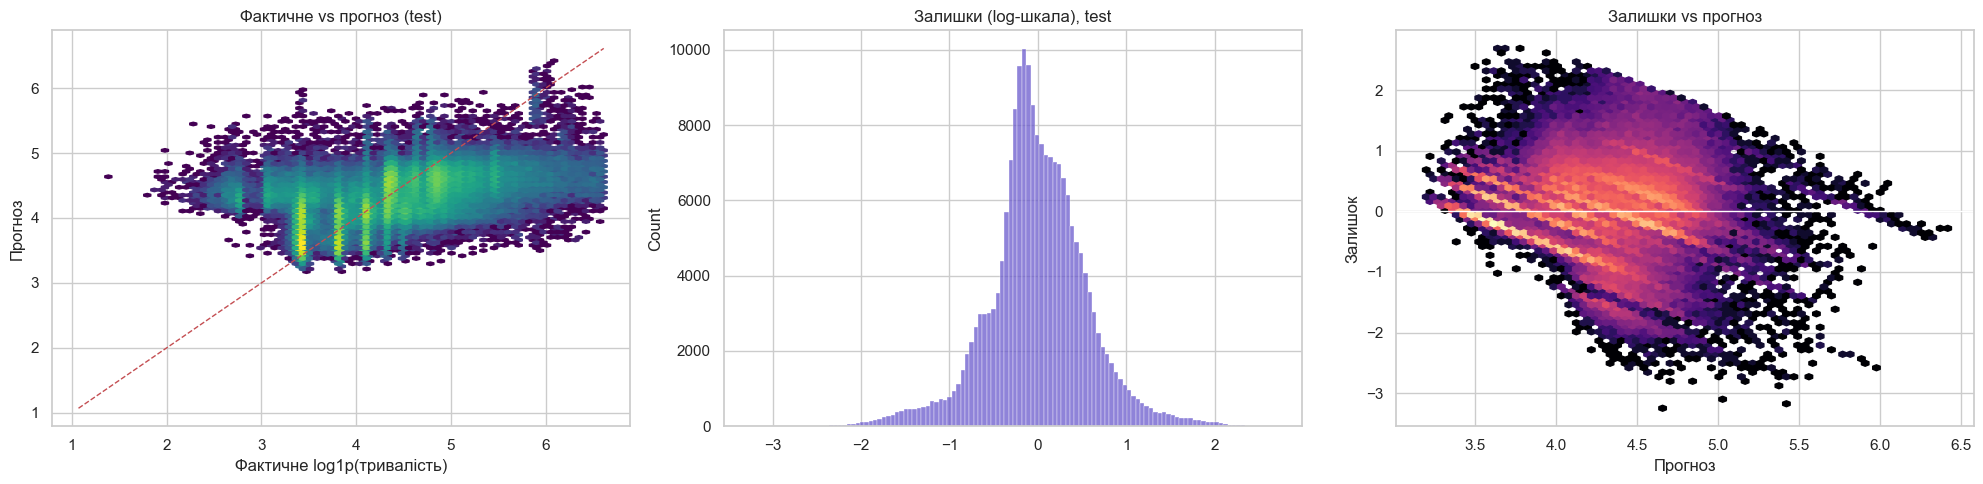

In [4]:
pred_test = model.predict(X_test)
sample = np.random.default_rng(SEED).choice(len(y_test), size=min(200_000, len(y_test)), replace=False)
resid = y_test[sample] - pred_test[sample]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].hexbin(y_test[sample], pred_test[sample], gridsize=70, bins="log", cmap="viridis")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set_xlabel("Фактичне log1p(тривалість)")
axes[0].set_ylabel("Прогноз")
axes[0].set_title("Фактичне vs прогноз (test)")
sns.histplot(resid, bins=120, ax=axes[1], color="slateblue")
axes[1].set_title("Залишки (log-шкала), test")
axes[2].hexbin(pred_test[sample], resid, gridsize=70, bins="log", cmap="magma")
axes[2].axhline(0, color="white", lw=1)
axes[2].set_xlabel("Прогноз")
axes[2].set_ylabel("Залишок")
axes[2].set_title("Залишки vs прогноз")
plt.tight_layout()
plt.show()

In [5]:
# Похибка в хвилинах за діапазонами фактичної тривалості
minutes = t_test["Duration_Minutes"].to_numpy()
bins = pd.cut(minutes, [0, 30, 60, 120, 240, 480, np.inf], labels=["≤30", "30–60", "60–120", "120–240", "240–480", ">480"])
pd.DataFrame({"діапазон, хв": bins, "фактична": minutes, "прогноз": np.expm1(pred_test)}).groupby("діапазон, хв", observed=True).agg(
    записів=("фактична", "size"), медіана_факт=("фактична", "median"), медіана_прогноз=("прогноз", "median"),
).assign(частка_pct=lambda d: (100 * d["записів"] / d["записів"].sum()).round(1)).round(1)

,записів,медіана_факт,медіана_прогноз,частка_pct
"діапазон, хв",,,,
≤30,353040,29.6,42.4,27.5
30–60,300225,45.0,51.8,23.4
60–120,361280,79.2,78.4,28.2
120–240,216808,142.5,94.1,16.9
240–480,40237,310.5,101.8,3.1
>480,11128,591.4,103.6,0.9


## 4. Коефіцієнти

Числові ознаки масштабовані (середнє 0, std 1), тож їхні коефіцієнти порівнянні: коефіцієнт β означає, що зміна ознаки на одне стандартне відхилення множить прогнозовану тривалість приблизно на $e^{\beta}$. Коефіцієнти one-hot категорій — відхилення від референсної (найрідшої) категорії.

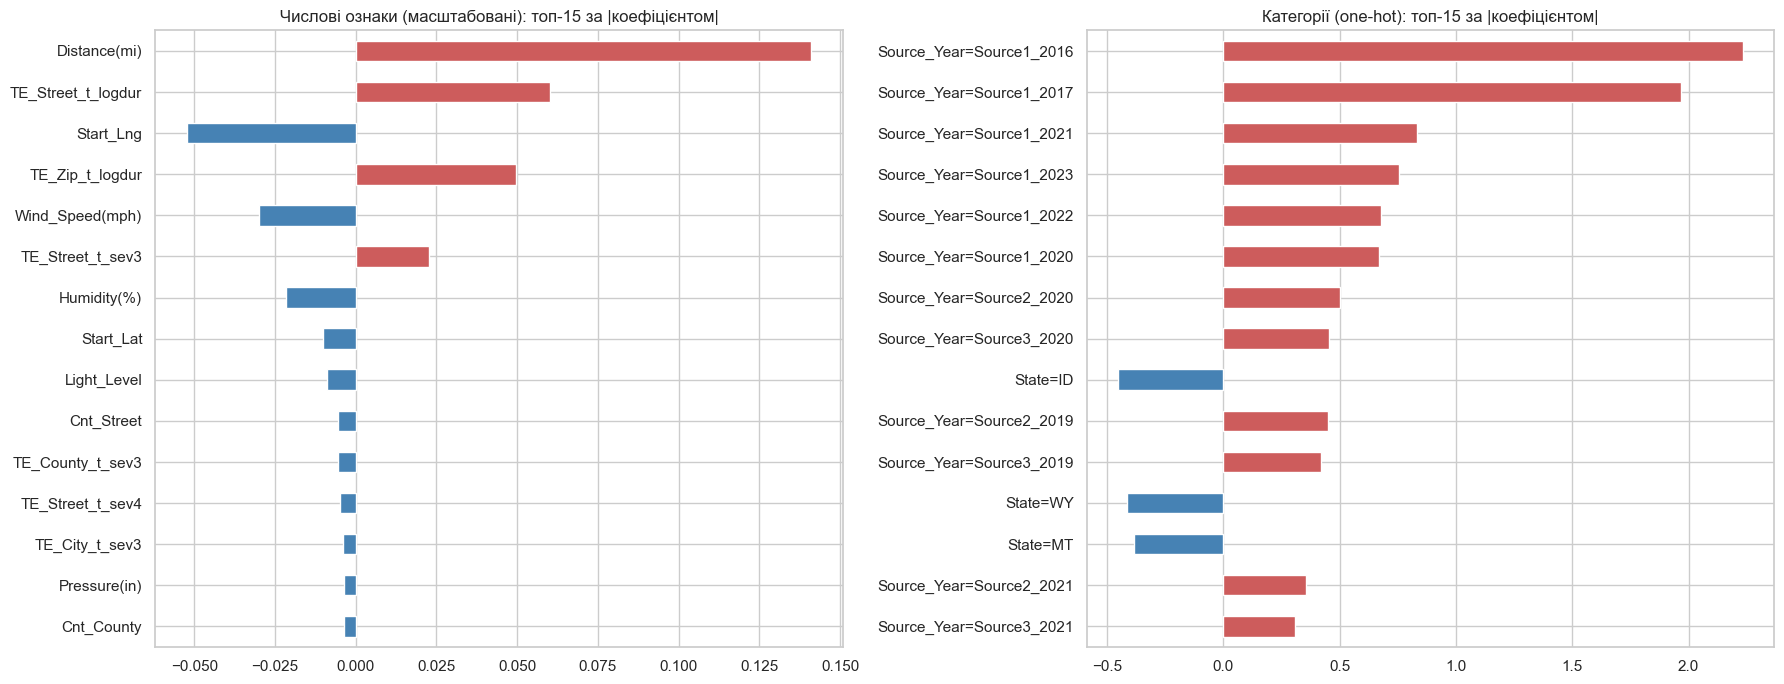

,коефіцієнт,множник тривалості e^β
Distance(mi),0.1411,1.152
TE_Street_t_logdur,0.0603,1.062
Start_Lng,-0.0523,0.949
TE_Zip_t_logdur,0.0497,1.051
Wind_Speed(mph),-0.0299,0.971
TE_Street_t_sev3,0.0229,1.023
Humidity(%),-0.0216,0.979
Start_Lat,-0.0100,0.990
Light_Level,-0.0089,0.991
Cnt_Street,-0.0054,0.995


In [6]:
coef = pd.Series(model.coef_, index=FEATURES)
num = coef[[f for f in meta["numeric_scaled"] if f in coef.index]].sort_values(key=np.abs, ascending=False).head(15)
cat = coef.drop(num.index, errors="ignore")
cat = cat[[f for f in cat.index if "=" in f]].sort_values(key=np.abs, ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, s, title in [(axes[0], num, "Числові ознаки (масштабовані)"), (axes[1], cat, "Категорії (one-hot)")]:
    s[::-1].plot.barh(ax=ax, color=["indianred" if v > 0 else "steelblue" for v in s[::-1]])
    ax.set_title(f"{title}: топ-15 за |коефіцієнтом|")
plt.tight_layout()
plt.show()
pd.DataFrame({"коефіцієнт": num.round(4), "множник тривалості e^β": np.exp(num).round(3)})

In [7]:
joblib.dump({"model": model, "features": FEATURES, "target": "Log_Duration", "inverse": "expm1"},
            MODELS_DIR / "regression_linear.joblib")
print("Збережено:", MODELS_DIR / "regression_linear.joblib")

Збережено: E:\OLeg\3curs\BigDataMining\data\models\regression_linear.joblib


## Висновки

| Модель (test) | R² (log) | RMSE (log) | MAE, хв | MedAE, хв |
|---|---|---|---|---|
| Baseline — середнє | 0.000 | 0.709 | 48.1 | 34.0 |
| **LinearRegression** | **0.352** | **0.571** | **37.7** | **19.4** |

* Модель пояснює **35% розкиду** логарифма тривалості і зменшує медіанну похибку з 34 до **19 хв** (−43%), середню — з 48 до 38 хв.
* **Перенавчання немає:** R² на train / valid / test — 0.353 / 0.353 / 0.352. Регуляризація не потрібна (4.5 млн записів на 230 ознак), а відсутність розриву між train і test підтверджує, що групове розбиття й out-of-fold target encoding не дали витоку.
* **Де модель помиляється:** типові тривалості (30–120 хв, ~79% записів) прогнозуються близько до факту (60–120 хв: медіана прогнозу 78 хв проти 79 фактичних), але довгі події систематично **недооцінюються** (240–480 хв: прогноз ~100 хв). Це «стягування до середнього», властиве лінійній моделі: рідкісні тривалі події не вирізняються ознаками, доступними на момент ДТП. Вертикальні смуги на графіку «факт vs прогноз» — шаблонні значення джерел (≈30 / 45 / 60 хв), які ознаки не пояснюють.
* **Найвпливовіші ознаки:** протяжність ділянки (`Distance`: +1 std → тривалість ×1.15), історична тривалість ДТП на цій вулиці та індексі (×1.06 і ×1.05), довгота (захід / схід країни), швидкість вітру й вологість (слабкий негативний ефект); серед категорій — джерело × рік (режими фіксації часу завершення).

**Що могло б покращити якість:** нелінійні моделі (градієнтний бустинг) для взаємодій ознак і довгого хвоста; окремі моделі для джерел із різними режимами фіксації часу.

Модель збережено: `data/models/regression_linear.joblib` (прогноз у хвилинах — `expm1(model.predict(X))`).